In [1]:
# Experiment 07 — Three-Qubit Fredkin (Controlled-SWAP) Gate

In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator
from qiskit.visualization import plot_histogram
import numpy as np

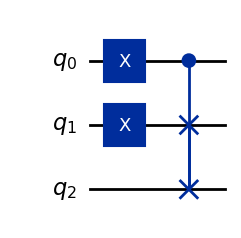

Statevector: [0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 1.+0.j 0.+0.j 0.+0.j]
Probabilities: {np.str_('101'): np.float64(1.0)}


In [3]:
# Create a three-qubit circuit
qc = QuantumCircuit(3)

# Set control qubit q0 and target qubit q1 to 1
qc.x(0)
qc.x(1)

# Apply controlled-SWAP
qc.cswap(0, 1, 2)

# Display the circuit
display(qc.draw("mpl"))

# Show the output state
state = Statevector.from_instruction(qc)

print("Statevector:", state.data)
print("Probabilities:", state.probabilities_dict())

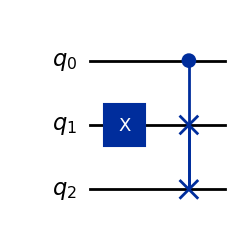

Statevector: [0.+0.j 0.+0.j 1.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j 0.+0.j]
Probabilities: {np.str_('010'): np.float64(1.0)}


In [4]:
# Create another three-qubit circuit
qc_zero = QuantumCircuit(3)

# Set target qubit q1 to 1
qc_zero.x(1)

# Apply controlled-SWAP with control qubit 0
qc_zero.cswap(0, 1, 2)

# Display the circuit
display(qc_zero.draw("mpl"))

# Show the output state
state_zero = Statevector.from_instruction(qc_zero)

print("Statevector:", state_zero.data)
print("Probabilities:", state_zero.probabilities_dict())

In [5]:
# Create a circuit containing only the Fredkin gate
fredkin = QuantumCircuit(3)
fredkin.cswap(0, 1, 2)

# Display its 8x8 matrix
matrix = Operator(fredkin).data

print("Fredkin Gate Matrix:")
print(np.real_if_close(matrix).astype(int))

Fredkin Gate Matrix:
[[1 0 0 0 0 0 0 0]
 [0 1 0 0 0 0 0 0]
 [0 0 1 0 0 0 0 0]
 [0 0 0 0 0 1 0 0]
 [0 0 0 0 1 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 1]]


Control = 1: {np.str_('101'): np.int64(1024)}


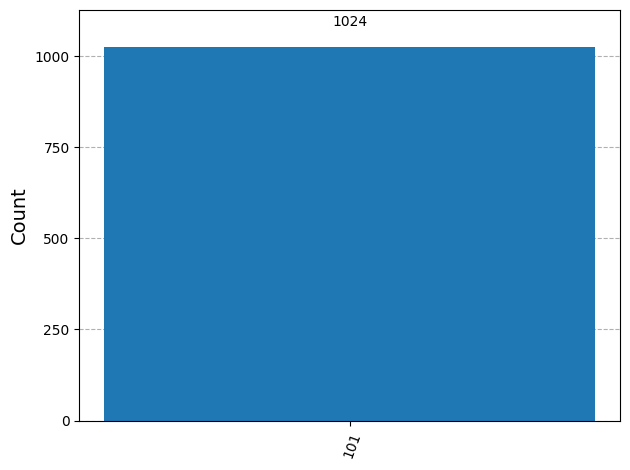

Control = 0: {np.str_('010'): np.int64(1024)}


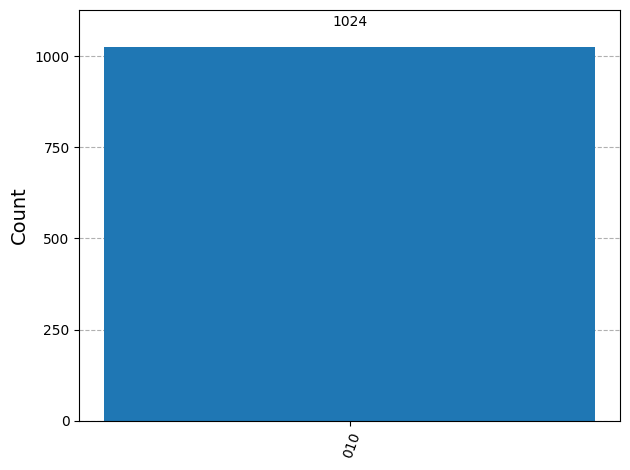

In [6]:
# Measure both output states
for name, output in [
    ("Control = 1", state),
    ("Control = 0", state_zero)
]:
    output.seed(42)
    counts = output.sample_counts(shots=1024)

    print(f"{name}:", counts)
    display(plot_histogram(counts))